In [1]:
library(rugarch)
library(WeightedPortTest)
library(FinTS)
library(ggplot2)
library(rmgarch)
library(xts)
library(checkmate)

Loading required package: parallel

Loading required package: zoo


Attaching package: ‘zoo’


The following objects are masked from ‘package:base’:

    as.Date, as.Date.numeric



Attaching package: ‘xts’


The following objects are masked from ‘package:rmgarch’:

    first, last




In [2]:
source('portfolio_modeling_functions.r')

Some features are not enabled in this build of Arrow. Run `arrow_info()` for more information.


Attaching package: ‘arrow’


The following object is masked from ‘package:utils’:

    timestamp




In [3]:
weekly_returns <- read_weekly_return_data(path="../datasets/SPY_XLU/seed_df.parquet", mod=TRUE, format="parquet")

In [4]:
train_boundaries <- get_train_boundaries(cutoff = '2022-01-01', weekly_returns = weekly_returns)
final_date <- as.Date(tail(weekly_returns$date, 1))

## Univariate Modeling

In [5]:
models <- list(
    'SPY' = NULL,
    'XLU' = NULL,
    'XLU.X' = NULL
)

probe_lags <- c(8,13,26)

### SPY ARMA(0,0)-eGARCH(1,1)

In [6]:
tic <- 'SPY'
fit_start = train_boundaries[1]
fit_end = train_boundaries[2]

model_config <- new_ugarch_config(
    model='eGARCH',
    ARCH_lags=1,
    GARCH_lags=1,
    AR_lags=0,
    MA_lags=0,
    dist='sstd'
)

SPY_ugarch_model <- run_experiment(model_config = model_config, tic=tic, fit_start = fit_start, fit_end = fit_end, weekly_returns=weekly_returns)
SPY_ugarch_model$fit

[1] "Std. resid. LB tests are good."
[1] "Std. resid. LiM tests are good."



*---------------------------------*
*          GARCH Model Fit        *
*---------------------------------*

Conditional Variance Dynamics 	
-----------------------------------
GARCH Model	: eGARCH(1,1)
Mean Model	: ARFIMA(0,0,0)
Distribution	: sstd 

Optimal Parameters
------------------------------------
        Estimate  Std. Error  t value Pr(>|t|)
mu       0.00144    0.000630   2.2832 0.022421
omega   -0.77595    0.080711  -9.6140 0.000000
alpha1  -0.27585    0.038018  -7.2558 0.000000
beta1    0.89993    0.010435  86.2442 0.000000
gamma1   0.28674    0.049636   5.7769 0.000000
skew     0.63632    0.034956  18.2033 0.000000
shape    4.80546    0.862976   5.5685 0.000000

Robust Standard Errors:
        Estimate  Std. Error  t value Pr(>|t|)
mu       0.00144    0.000639   2.2513 0.024365
omega   -0.77595    0.076190 -10.1845 0.000000
alpha1  -0.27585    0.048386  -5.7011 0.000000
beta1    0.89993    0.009556  94.1704 0.000000
gamma1   0.28674    0.051143   5.6067 0.000000
skew    

SPY ARMA(0,0)-eGARCH(1,1)
- No unmodeled effects
- Significant, stable parameters
- BIC: -5.17

In [7]:
models[['SPY']] <- SPY_ugarch_model

### XLU ARMA(0,0)-eGARCH(1,1)

In [8]:
tic <- 'XLU'
fit_start = train_boundaries[1]
fit_end = train_boundaries[2]

model_config <- new_ugarch_config(
    model='eGARCH',
    ARCH_lags=1,
    GARCH_lags=1,
    AR_lags=0,
    MA_lags=0,
    dist='sstd'
)

XLU_ugarch_model_11 <- run_experiment(model_config = model_config, tic=tic, fit_start = fit_start, fit_end = fit_end, weekly_returns=weekly_returns)
XLU_ugarch_model_11$fit

[1] "Std. resid. LB tests are good."
[1] "Exception in Std. resid. LiM test with lag_3 -> p-value: 0.0443872690742176"



*---------------------------------*
*          GARCH Model Fit        *
*---------------------------------*

Conditional Variance Dynamics 	
-----------------------------------
GARCH Model	: eGARCH(1,1)
Mean Model	: ARFIMA(0,0,0)
Distribution	: sstd 

Optimal Parameters
------------------------------------
        Estimate  Std. Error  t value Pr(>|t|)
mu      0.001407    0.000634   2.2193 0.026467
omega  -1.248910    0.447605  -2.7902 0.005268
alpha1 -0.206398    0.050764  -4.0659 0.000048
beta1   0.839615    0.057502  14.6014 0.000000
gamma1  0.250263    0.081295   3.0785 0.002081
skew    0.842573    0.040634  20.7354 0.000000
shape   6.134540    1.349515   4.5457 0.000005

Robust Standard Errors:
        Estimate  Std. Error  t value Pr(>|t|)
mu      0.001407    0.000563   2.4989 0.012457
omega  -1.248910    0.659982  -1.8923 0.058446
alpha1 -0.206398    0.060460  -3.4138 0.000641
beta1   0.839615    0.084879   9.8918 0.000000
gamma1  0.250263    0.092586   2.7030 0.006871
skew    

In [9]:
z <- XLU_ugarch_model_11$z
h <- XLU_ugarch_model_11$h
run_LiM_tests(z = z, h=h,lags = c(3,4,5,6,7), identifier = "Std. resid.", exceptional_event = 'sig')

[1] "Exception in Std. resid. LiM test with lag_3 -> p-value: 0.0443872690742176"


$lag_3
Approximate p-value 
         0.04438727 

$lag_4
Approximate p-value 
         0.05877145 

$lag_5
Approximate p-value 
         0.09407108 

$lag_6
Approximate p-value 
         0.09547421 

$lag_7
Approximate p-value 
           0.130409

XLU ARMA(0,0)-eGARCH(1,1)
- Unmodeled conditional heteroskedasticity detected at lag 3 (4,5,6,7 are fine, so are all lags with the ARCH-LM test)
- Significant, stable parameters
- BIC: -5.00

### XLU ARMA(0,0)-eGARCH(2,1)

In [10]:
tic <- 'XLU'
fit_start = train_boundaries[1]
fit_end = train_boundaries[2]

model_config <- new_ugarch_config(
    model='eGARCH',
    ARCH_lags=2,
    GARCH_lags=1,
    AR_lags=0,
    MA_lags=0,
    dist='sstd'
)

XLU_ugarch_model_21 <- run_experiment(model_config = model_config, tic=tic, fit_start = fit_start, fit_end = fit_end, weekly_returns=weekly_returns)
XLU_ugarch_model_21$fit

[1] "Std. resid. LB tests are good."
[1] "Std. resid. LiM tests are good."



*---------------------------------*
*          GARCH Model Fit        *
*---------------------------------*

Conditional Variance Dynamics 	
-----------------------------------
GARCH Model	: eGARCH(2,1)
Mean Model	: ARFIMA(0,0,0)
Distribution	: sstd 

Optimal Parameters
------------------------------------
        Estimate  Std. Error  t value Pr(>|t|)
mu      0.001426    0.000606  2.35236 0.018655
omega  -0.755413    0.847185 -0.89167 0.372567
alpha1 -0.194320    0.025546 -7.60655 0.000000
alpha2  0.022319    0.055551  0.40178 0.687846
beta1   0.902973    0.108933  8.28924 0.000000
gamma1  0.285729    0.072554  3.93816 0.000082
gamma2 -0.114201    0.115015 -0.99293 0.320746
skew    0.844275    0.033900 24.90515 0.000000
shape   6.168285    1.355994  4.54890 0.000005

Robust Standard Errors:
        Estimate  Std. Error  t value Pr(>|t|)
mu      0.001426    0.001056  1.34938 0.177215
omega  -0.755413    2.851631 -0.26491 0.791082
alpha1 -0.194320    0.190640 -1.01930 0.308059
alpha2  

XLU ARMA(0,0)-eGARCH(2,1)
- No unmodeled effects
- Stable parameters, many insignificant parameters (especially under Robust Standard Errors)
- BIC: -4.98

### XLU ARMA(0,0)-eGARCH(1,2)

In [11]:
tic <- 'XLU'
fit_start = train_boundaries[1]
fit_end = train_boundaries[2]

model_config <- new_ugarch_config(
    model='eGARCH',
    ARCH_lags=1,
    GARCH_lags=2,
    AR_lags=0,
    MA_lags=0,
    dist='sstd'
)

XLU_ugarch_model_12 <- run_experiment(model_config = model_config, tic=tic, fit_start = fit_start, fit_end = fit_end, weekly_returns=weekly_returns)
XLU_ugarch_model_12$fit

[1] "Std. resid. LB tests are good."
[1] "Std. resid. LiM tests are good."



*---------------------------------*
*          GARCH Model Fit        *
*---------------------------------*

Conditional Variance Dynamics 	
-----------------------------------
GARCH Model	: eGARCH(1,2)
Mean Model	: ARFIMA(0,0,0)
Distribution	: sstd 

Optimal Parameters
------------------------------------
        Estimate  Std. Error   t value Pr(>|t|)
mu      0.001413    0.000624  2.263599 0.023599
omega  -1.184309    0.665385 -1.779886 0.075095
alpha1 -0.208724    0.071054 -2.937532 0.003308
beta1   0.785523    0.711449  1.104117 0.269542
beta2   0.062364    0.774584  0.080513 0.935830
gamma1  0.247512    0.083366  2.968965 0.002988
skew    0.842848    0.045814 18.397215 0.000000
shape   6.107378    1.338034  4.564441 0.000005

Robust Standard Errors:
        Estimate  Std. Error  t value Pr(>|t|)
mu      0.001413    0.000809  1.74558 0.080884
omega  -1.184309    2.790114 -0.42447 0.671226
alpha1 -0.208724    0.220826 -0.94520 0.344558
beta1   0.785523    3.341394  0.23509 0.814140

XLU ARMA(0,0)-eGARCH(2,1)
- No unmodeled effects
- Stable parameters, many insignificant parameters (especially under Robust Standard Errors)
- BIC: -4.99

### XLU Model Selection

Even though there appears to be a rejection of the null of the weighted Li-Mak test at lag 3, the (1,1) model results in more significant parameters as well as a better BIC value. Therefore a garch order of (1,1) will be preferred over (2,1) and (1,2).

In [12]:
models[['XLU']] <- XLU_ugarch_model_11

### XLU ARMAX(0,0)-eGARCH(1,1)

In [13]:
tic <- 'XLU'
fit_start = train_boundaries[1]
fit_end = train_boundaries[2]
mean_x_reg <- get_tic_weekly_returns(tic='SPY', start_date = fit_start, end_date =final_date, weekly_returns = weekly_returns)

model_config <- new_ugarch_config(
    model='eGARCH',
    ARCH_lags=1,
    GARCH_lags=1,
    AR_lags=0,
    MA_lags=0,
    dist='sstd',
    mean_x_reg=mean_x_reg
)

XLUX_ugarch_model <- run_experiment(tic=tic, fit_start = fit_start, fit_end = fit_end, model_config = model_config, , weekly_returns=weekly_returns)
XLUX_ugarch_model$fit

[1] "Std. resid. LB tests are good."
[1] "Std. resid. LiM tests are good."



*---------------------------------*
*          GARCH Model Fit        *
*---------------------------------*

Conditional Variance Dynamics 	
-----------------------------------
GARCH Model	: eGARCH(1,1)
Mean Model	: ARFIMA(0,0,0)
Distribution	: sstd 

Optimal Parameters
------------------------------------
        Estimate  Std. Error  t value Pr(>|t|)
mu      0.000661    0.000560   1.1800 0.237983
mxreg1  0.588210    0.027176  21.6444 0.000000
omega  -0.226211    0.032579  -6.9434 0.000000
alpha1  0.023295    0.022237   1.0476 0.294833
beta1   0.972390    0.004050 240.1243 0.000000
gamma1  0.142431    0.054210   2.6274 0.008605
skew    0.882682    0.043286  20.3919 0.000000
shape  10.213643    3.327553   3.0694 0.002145

Robust Standard Errors:
        Estimate  Std. Error   t value Pr(>|t|)
mu      0.000661    0.000592   1.11742 0.263814
mxreg1  0.588210    0.039438  14.91466 0.000000
omega  -0.226211    0.060106  -3.76352 0.000168
alpha1  0.023295    0.030043   0.77537 0.438121
bet

#### Rolling OLS Analysis

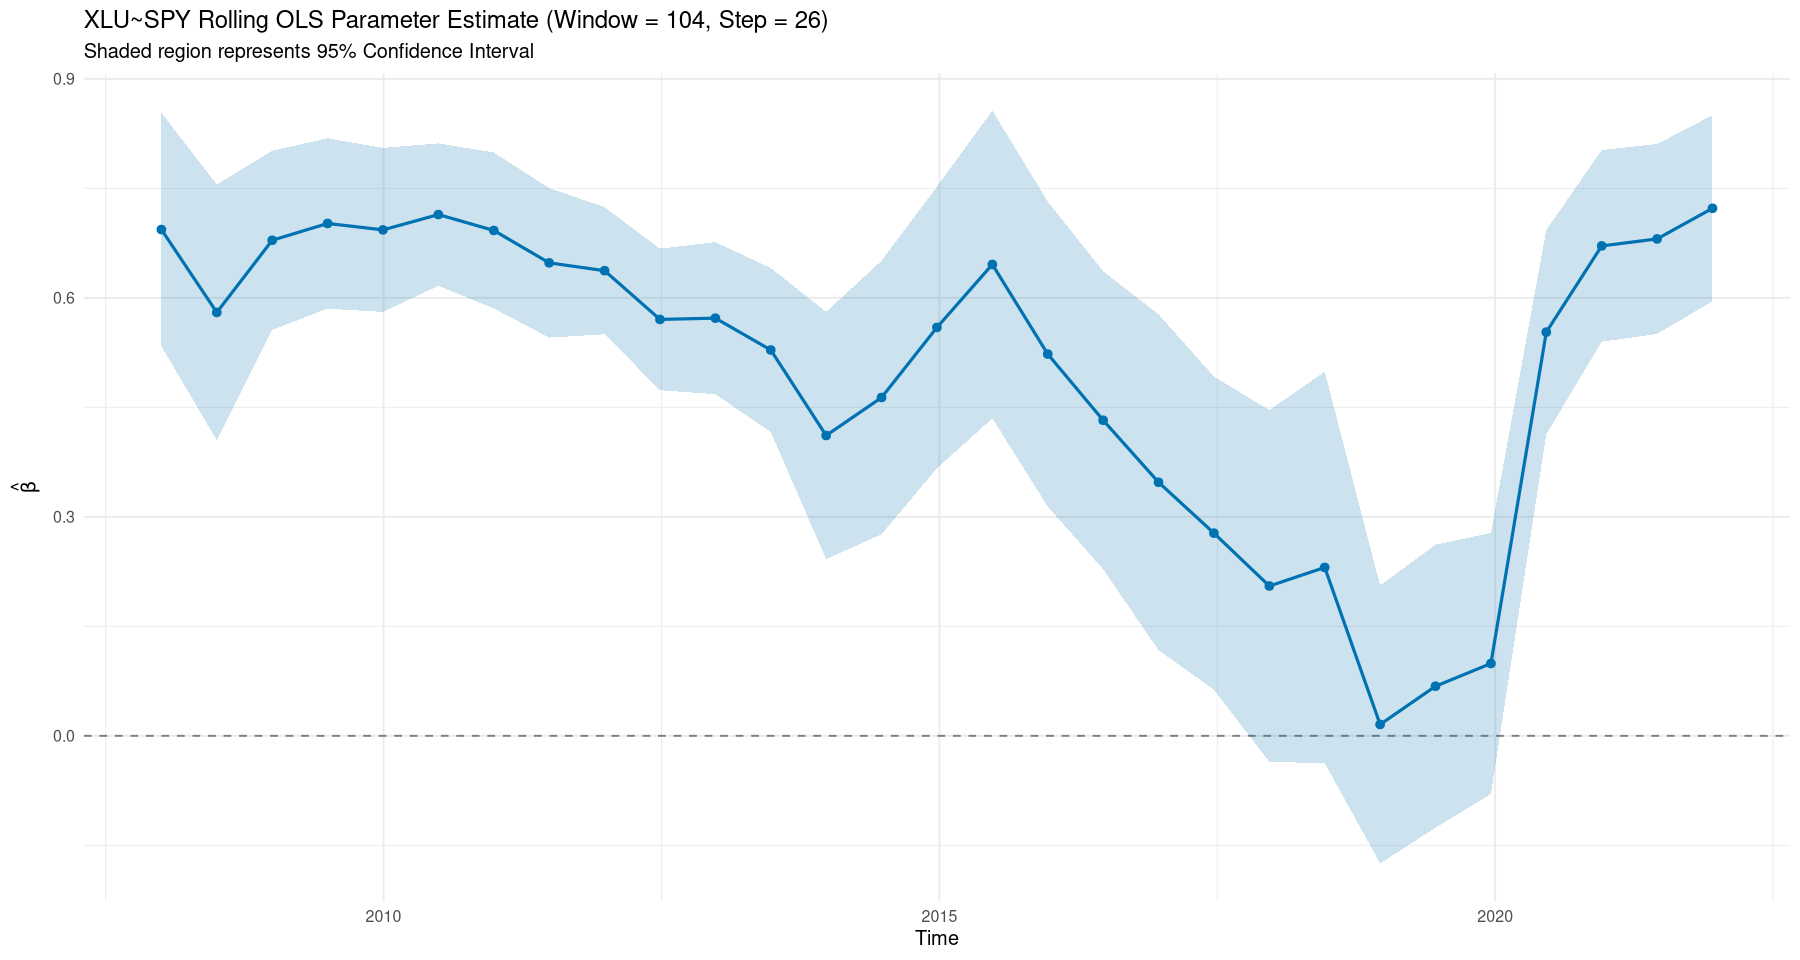

In [14]:
tic <- 'XLU'
market_tic <- 'SPY'

window_size <- 104
step_size <- 26

plot_rolling_ols_graph(weekly_returns = weekly_returns,response_tic = tic, regressor_tic = market_tic)

XLU ARMAX(0,0)-eGARCH(1,2)
- No unmodeled effects
- The Nyblom stability test shows no unstable parameters, however a rolling OLS analysis reveals a non-constant $XLU \sim SPY$ regression relationship
- Some insignificant parameters
- BIC: -5.2866

In [15]:
models[['XLU.X']] <- XLUX_ugarch_model

## Multivariate Modeling

In [16]:
multivariate_models <- list(
    'SPY_XLU'=NULL,
    'SPY_XLU.X'=NULL
)

### SPY | XLU

In [17]:
subjects <- c('SPY', 'XLU')

fit_start = train_boundaries[1]
fit_end = train_boundaries[2]

check_DCC_effects_in_z(subjects = subjects, models = models)

# Univariate Specs
uspecs <- list(
    models[[subjects[1]]]$spec,
    models[[subjects[2]]]$spec
)

model_config <- new_mgarch_config(
    uspecs=uspecs,
    model='DCC',
    dccOrder=c(1,1),
    distribution='mvt',
    solver=c("hybrid", "solnp"),
    subjects=subjects
)

model <- run_experiment(model_config, fit_start = fit_start, fit_end = fit_end, probe_lags = c(8,13,26), weekly_returns=weekly_returns)
multivariate_models[[paste(subjects,collapse = '_')]] <- model

model$fit

[1] "SPY|XLU -- Std. Resid. DCC Test"
       lag_8      lag_13       lag_26
 0.001727022 0.001093729 1.837685e-09
[1] "SPY Corr. Adj. Resid. LB tests are good."
[1] "SPY Corr. Adj. Resid. LiM tests are good."
[1] "XLU Corr. Adj. Resid. LB tests are good."
[1] "XLU Corr. Adj. Resid. LiM tests are good."
[1] "SPY|XLU Corr. Adj. Resid. DCC tests are good."



*---------------------------------*
*          DCC GARCH Fit          *
*---------------------------------*

Distribution         :  mvt
Model                :  DCC(1,1)
No. Parameters       :  18
[VAR GARCH DCC UncQ] : [0+14+3+1]
No. Series           :  2
No. Obs.             :  834
Log-Likelihood       :  4372.779
Av.Log-Likelihood    :  5.24 

Optimal Parameters
-----------------------------------
               Estimate  Std. Error  t value Pr(>|t|)
[SPY].mu       0.001440    0.000700   2.0578 0.039609
[SPY].omega   -0.775955    0.061441 -12.6293 0.000000
[SPY].alpha1  -0.275853    0.038683  -7.1311 0.000000
[SPY].beta1    0.899927    0.008107 111.0027 0.000000
[SPY].gamma1   0.286743    0.047548   6.0306 0.000000
[SPY].skew     0.636317    0.037378  17.0237 0.000000
[SPY].shape    4.805465    0.652286   7.3671 0.000000
[XLU].mu       0.001407    0.000616   2.2835 0.022398
[XLU].omega   -1.248910    0.705475  -1.7703 0.076676
[XLU].alpha1  -0.206398    0.059474  -3.4704 0.000520
[

There is clear evidence of DCC effects as per the DCCTest. The resulting model has overall significant parameters. The significance of the DCC parameters (`dcca1`: 0.096, `dccb1`: 0.00) talks to the significance of the second stage DCC model. The significance of the `mshape` parameter supports the choice of `mvt` as the multivariate innovation distribution. The correlation adjusted residuals exhibit no univariate unmodeled effects in any of the tested lags (including the previously problematic lag 26 for XLU). The only exception is at lag 26 where there appears to be some left over DCC.

### SPY | XLU.X

In [18]:
subjects <- c('SPY', 'XLU.X')
tic_codes <- c('SPY', 'XLU')

fit_start = train_boundaries[1]
fit_end = train_boundaries[2]

check_DCC_effects_in_z(subjects = subjects, models = models)

# Univariate Specs
uspecs <- list(
    models[[subjects[1]]]$spec,
    models[[subjects[2]]]$spec
)

model_config <- new_mgarch_config(
    uspecs=uspecs,
    model='DCC',
    dccOrder=c(1,1),
    distribution='mvt',
    solver=c("hybrid", "solnp"),
    subjects=subjects
)

model <- run_experiment(model_config, fit_start = fit_start, fit_end = fit_end, probe_lags = c(8,13,26), tic_codes = tic_codes, weekly_returns=weekly_returns)
multivariate_models[[paste(subjects,collapse = '_')]] <- model

model$fit

[1] "SPY|XLU.X -- Std. Resid. DCC Test"
     lag_8    lag_13     lag_26
 0.2342812 0.3147204 0.06663404
[1] "NOTICE: Using tic codes SPY,XLU"
[1] "SPY Corr. Adj. Resid. LB tests are good."
[1] "SPY Corr. Adj. Resid. LiM tests are good."
[1] "XLU.X Corr. Adj. Resid. LB tests are good."
[1] "XLU.X Corr. Adj. Resid. LiM tests are good."
[1] "SPY|XLU.X Corr. Adj. Resid. DCC tests are good."



*---------------------------------*
*          DCC GARCH Fit          *
*---------------------------------*

Distribution         :  mvt
Model                :  DCC(1,1)
No. Parameters       :  19
[VAR GARCH DCC UncQ] : [0+15+3+1]
No. Series           :  2
No. Obs.             :  834
Log-Likelihood       :  4383.992
Av.Log-Likelihood    :  5.26 

Optimal Parameters
-----------------------------------
                Estimate  Std. Error   t value Pr(>|t|)
[SPY].mu        0.001440    0.000702   2.05200 0.040170
[SPY].omega    -0.775955    0.062248 -12.46560 0.000000
[SPY].alpha1   -0.275853    0.038995  -7.07406 0.000000
[SPY].beta1     0.899927    0.008224 109.42424 0.000000
[SPY].gamma1    0.286743    0.047414   6.04761 0.000000
[SPY].skew      0.636317    0.037303  17.05805 0.000000
[SPY].shape     4.805465    0.670097   7.17130 0.000000
[XLU.X].mu      0.000661    0.000581   1.13808 0.255085
[XLU.X].mxreg1  0.588210    0.037925  15.50995 0.000000
[XLU.X].omega  -0.226211    0.06676

As per the DCCTest, there don't seem to be very strong DCC effects between the std. residuals of the univariate SPY and XLU.X models. This is not surprising, the exogenous SPY term in the XLU.X mean model is expected to soak up most of the correlation. The resulting model has a worse picture of parameter significance. The significance of the DCC parameters (pval_dcca1: 0.319, pval_dccb1: 0.261) reinforce the notion that a second stage DCC model is not necessarily required between SPY and XLU.X.

### Rolling Correlation Analysis

#### SPY | XLU

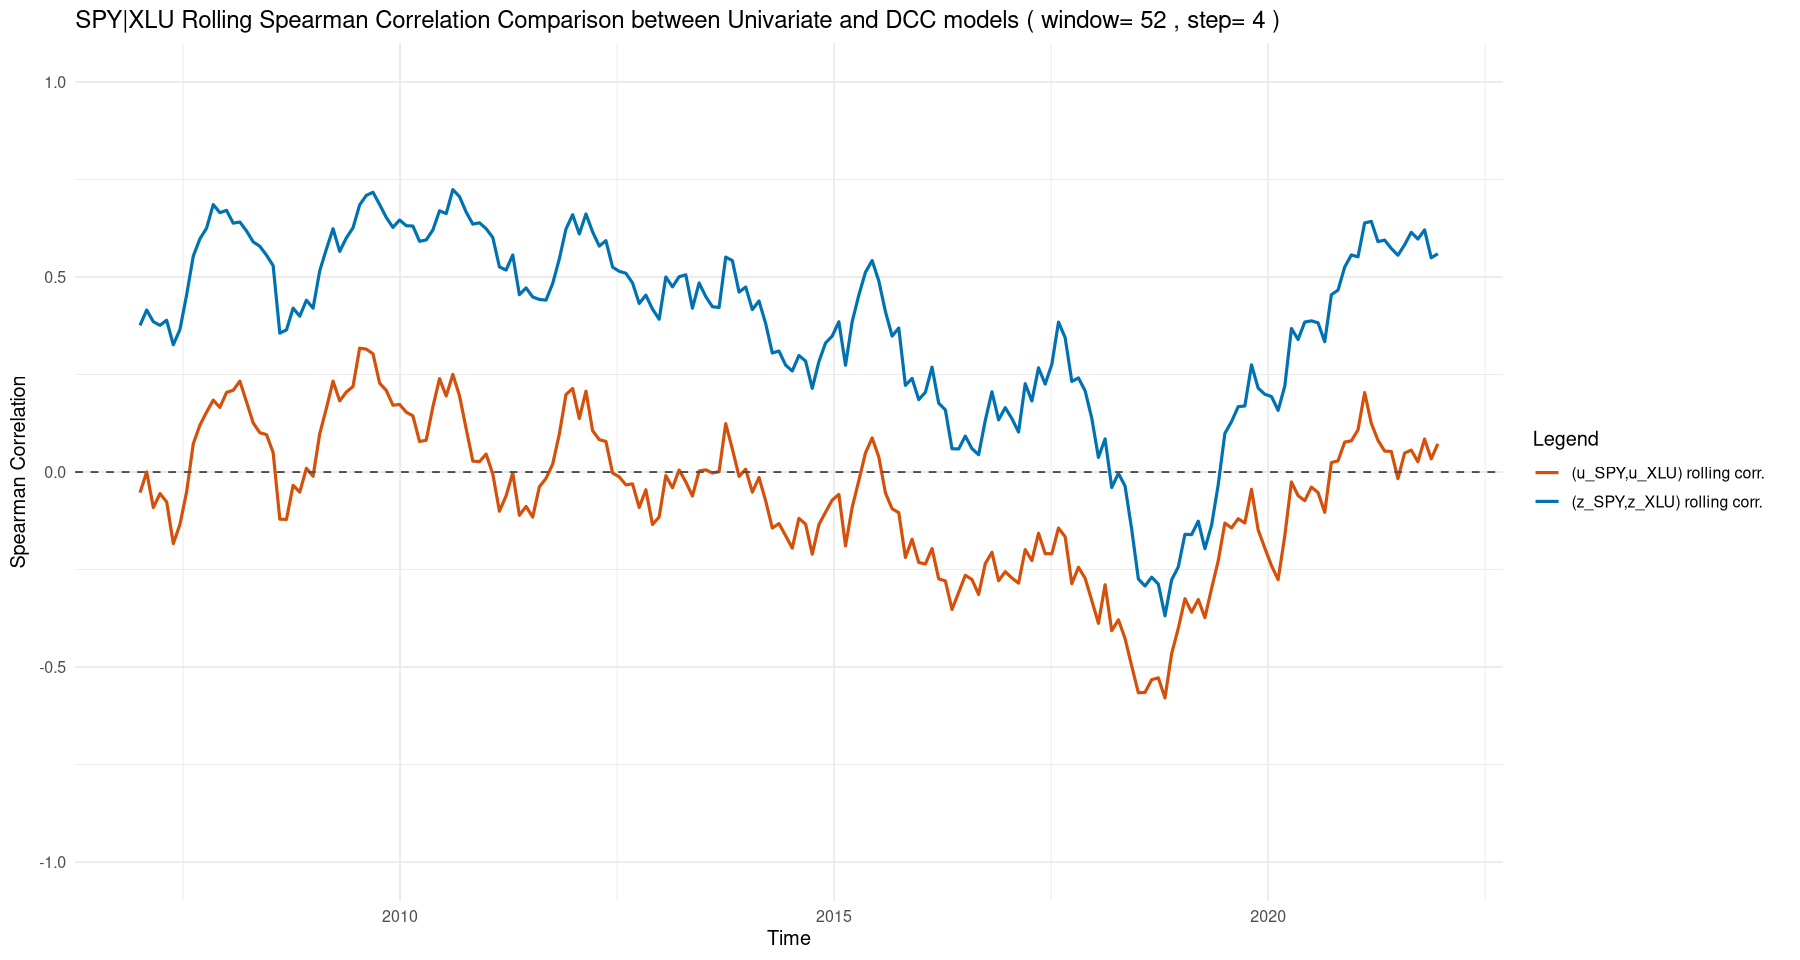

In [19]:
subjects <- c('SPY', 'XLU')
window_size = 52
step_size = 4

model <- multivariate_models[[paste(subjects,collapse = '_')]]

plot_rolling_corr_comparison_graph(multivariate_model = model, window_size = window_size , step_size = step_size)

#### SPY | XLU.X

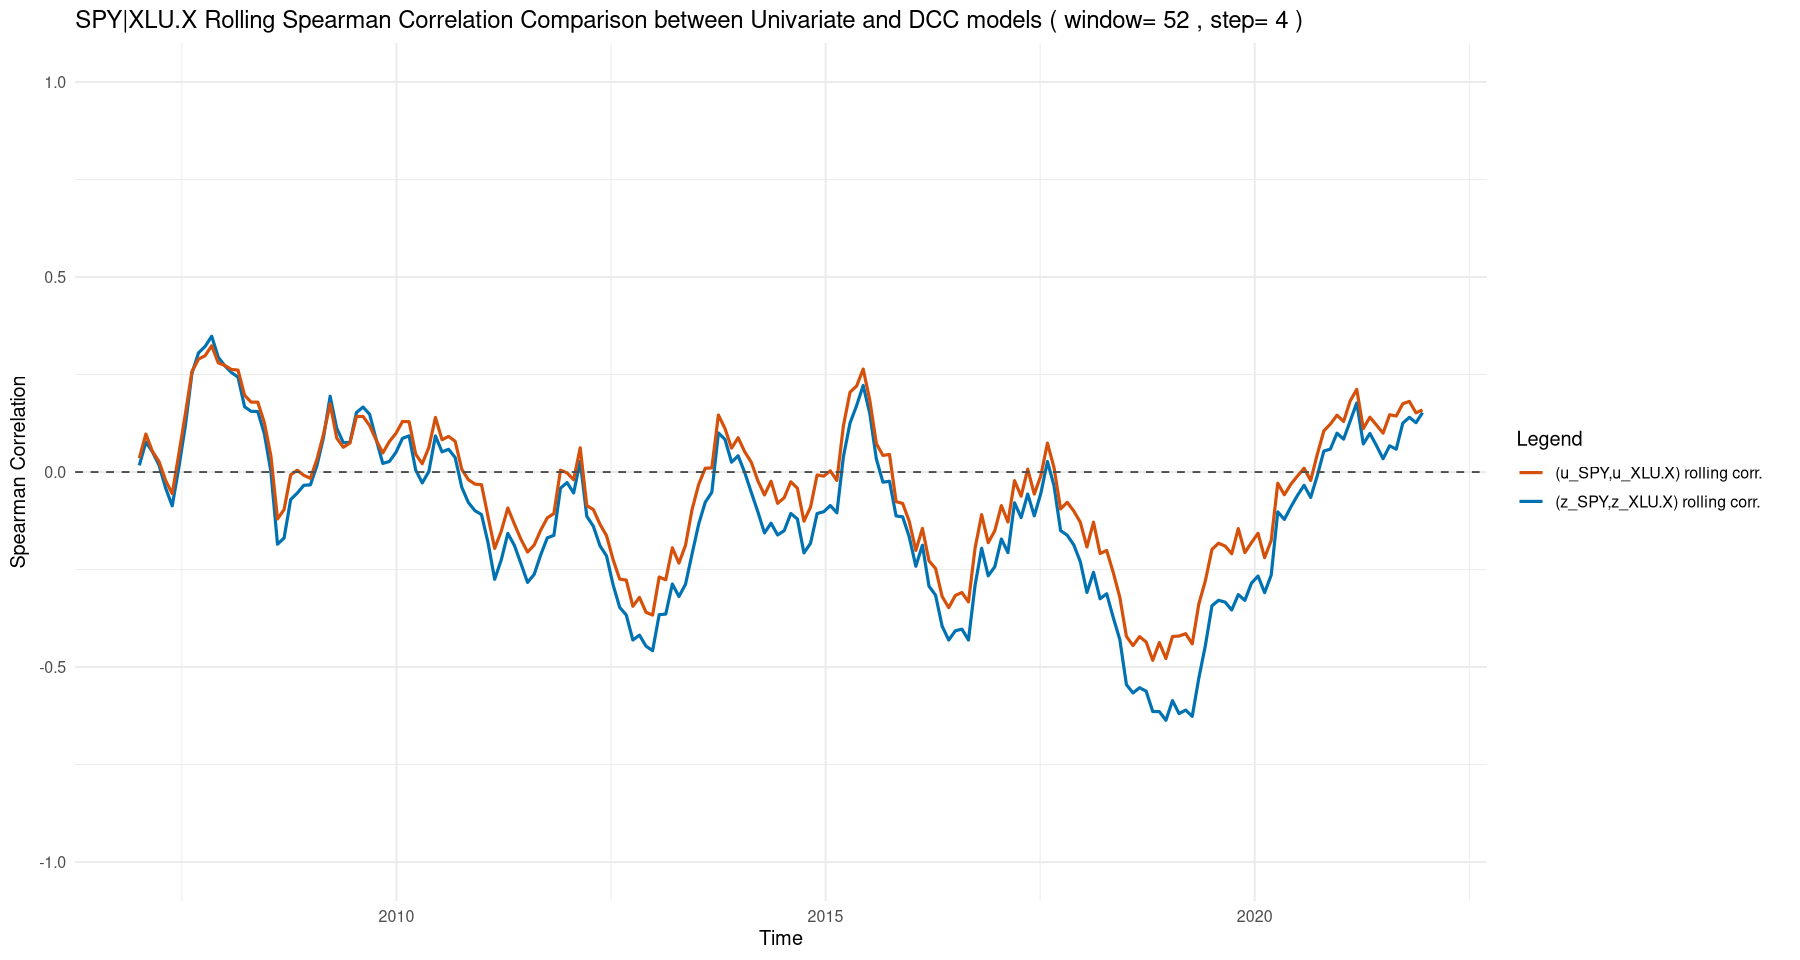

In [20]:
subjects <- c('SPY', 'XLU.X')
window_size = 52
step_size = 4

model <- multivariate_models[[paste(subjects,collapse = '_')]]

plot_rolling_corr_comparison_graph(multivariate_model = model, window_size = window_size , step_size = step_size)

## Conclusion

The SPY|XLU DCC model results in a clear reduction in the rolling correlation between the innovations of the univariate models, whereas the SPY|XLU.X DCC model barely affects them. The reduction in rolling correlation, along with the p values of the relevant parameters imply that the DCC model is able to successfully explain a significant portion of the correlation between innovations.

The resulting rolling correlation achieved by the SPY|XLU DCC model and the univariate SPY|XLU.X model appear to be roughly equivalent. The univariate model SPY|XLU.X technically has fewer parameters, and with 834 training observations might be the preferable option in certain cases. However,
- the advantage of including dynamic correlation information in the state space
- the instability of the regression relationship between SPY and XLU (as evidenced by rolling OLS analysis)
- the two stage fitting of the DCC model limiting the further demand on available data points

the SPY|XLU DCC(1,1,mvt)-eGARCH(1,1,sstd) model is the most fitting for use in this study